### Results and analysis of sim runs can be found here

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split

In [11]:
df = pd.read_csv(r"trips_all.csv")
df.columns

Index(['experiment', 'description', 'world', 'arm', 'seed', 'bonus_strength',
       'phase', 'trip', 'party', 'entry', 'target', 'start_tick', 'end_tick',
       'hours', 'outcome', 'end_reason', 'leopard_found', 'closest_approach_m',
       'poacher_success', 'ranger_failed', 'reward', 'epsilon', 'trip_index',
       'caught', 'timed_out', 'start_hour', 'mean_loss', 'mean_q',
       'lessons_active', 'w_avoid_villages', 'w_avoid_station_area',
       'w_avoid_high_centrality', 'w_prefer_low_viewshed',
       'w_avoid_capture_sites', 'w_avoid_threat_cells'],
      dtype='object')

In [7]:
# Isolate v5,4 w/o dusk, and v3 experiments
VERSIONS = {"ablation_v3": "v3", "ablation_v4_realistic": "v4", "ablation_v5_rb2": "v5"}
# Simplify w/ version column
df = df[df["experiment"].isin(VERSIONS)].copy()
df["version"] = df["experiment"].map(VERSIONS)

In [ ]:
# Train test split
train = df[df["phase"] == "train"]
eval_ = df[df["phase"] == "eval"]
# Drop empty columns
trail = train.dropna(axis = 1, how = "all")
eval_ = eval_.dropna(axis = 1, how = "all")

np.float64(0.21716066015493432)

In [9]:
# Total rows after scoping
print(f"Total rows after scope = {len(df)}. Expecting 62,872")

# Trips per version and phase
df.groupby(["version", "phase"]).size().unstack()

# Expected...
#   version	  eval	 train
#     v3	 6,589	28,883
#     v4	 4,310	16,146
#     v5	   977	 5,967

Total rows after scope = 62872. Expecting 62,872


phase,eval,train
version,,
v3,6589,28883
v4,4310,16146
v5,977,5967


In [ ]:
# Seeds per arm and version
df.groupby(["arm", "version"])["seed"].nunique().unstack()

In [ ]:
# Eval Table
# One row per run(version × arm × seed) for every eval trip
runs = (
    eval_
    .groupby(["version", "arm", "seed"])
    .agg(
        trips=("trip", "size"),
        success=('poacher_success', 'mean'),
        caught=('caught', 'mean'),
        timed_out=('timed_out', 'mean'),
        hours=('hours', 'mean'),
    )
    .reset_index() # turns the group keys back into ordinary columns
)
len(runs)

90

In [ ]:
runs[(runs["version"] == "v4") & (runs["arm"] == "dqn_move_only")]

,version,arm,seed,trips,success,caught,timed_out,hours
60,v4,dqn_move_only,1,134,0.305970,0.298507,0.082090,11.675373
61,v4,dqn_move_only,2,121,0.322314,0.272727,0.074380,15.090909
62,v4,dqn_move_only,3,133,0.345865,0.203008,0.045113,11.775188
63,v4,dqn_move_only,4,131,0.274809,0.427481,0.076336,12.486260
64,v4,dqn_move_only,5,140,0.264286,0.307143,0.021429,9.055000


In [ ]:
# Compute mean and std of successful trips for every arm in each version
runs.groupby(['version', 'arm']).success.agg(["mean", "std"])

mean       std
version arm                               
v3      dqn_full        0.085616  0.026205
        dqn_full_road   0.091017  0.022818
        dqn_knowledge   0.242543  0.111014
        dqn_move_only   0.279284  0.076647
        dqn_move_road   0.309116  0.057563
        rb_every_trip   0.209633  0.027199
        rb_outcomes     0.196298  0.067024
        shortest_path   0.352000  0.024648
        wanderer        0.070500  0.018741
v4      dqn_full        0.098817  0.040065
        dqn_full_road   0.118960  0.030808
        dqn_knowledge   0.173999  0.095039
        dqn_move_only   0.302649  0.033586
        dqn_move_road   0.274630  0.046395
        shortest_path   0.357123  0.029329
        wanderer        0.070222  0.015971
v5      rb2_every_trip  0.260383  0.071678
        rb2_outcomes    0.256591  0.046373

In [ ]:
#Reconciled against sim summary calculations
check = pd.read_csv(r"runs_all.csv")
check["version"] = check["experiment"].map(VERSIONS)
merged = runs.merge(check, on=["version", "arm", "seed"])
print(len(merged), (merged["success"].round(3) - merged["poacher_success_rate"]).abs().max())

90 0.0


In [27]:
# Identify success rates, smoothing with average of previous trip samples
curves = train[train["trip_index"] <= 500].sort_values("trip_index").copy()

curves["rolling_success"] = (
    curves.groupby(["version", "arm", "seed"])["poacher_success"].transform(lambda s: s.astype(float).rolling(50).mean())
)
curves.columns

Index(['experiment', 'description', 'world', 'arm', 'seed', 'bonus_strength',
       'phase', 'trip', 'party', 'entry', 'target', 'start_tick', 'end_tick',
       'hours', 'outcome', 'end_reason', 'leopard_found', 'closest_approach_m',
       'poacher_success', 'ranger_failed', 'reward', 'epsilon', 'trip_index',
       'caught', 'timed_out', 'start_hour', 'mean_loss', 'mean_q',
       'lessons_active', 'w_avoid_villages', 'w_avoid_station_area',
       'w_avoid_high_centrality', 'w_prefer_low_viewshed',
       'w_avoid_capture_sites', 'w_avoid_threat_cells', 'version',
       'rolling_success'],
      dtype='object')

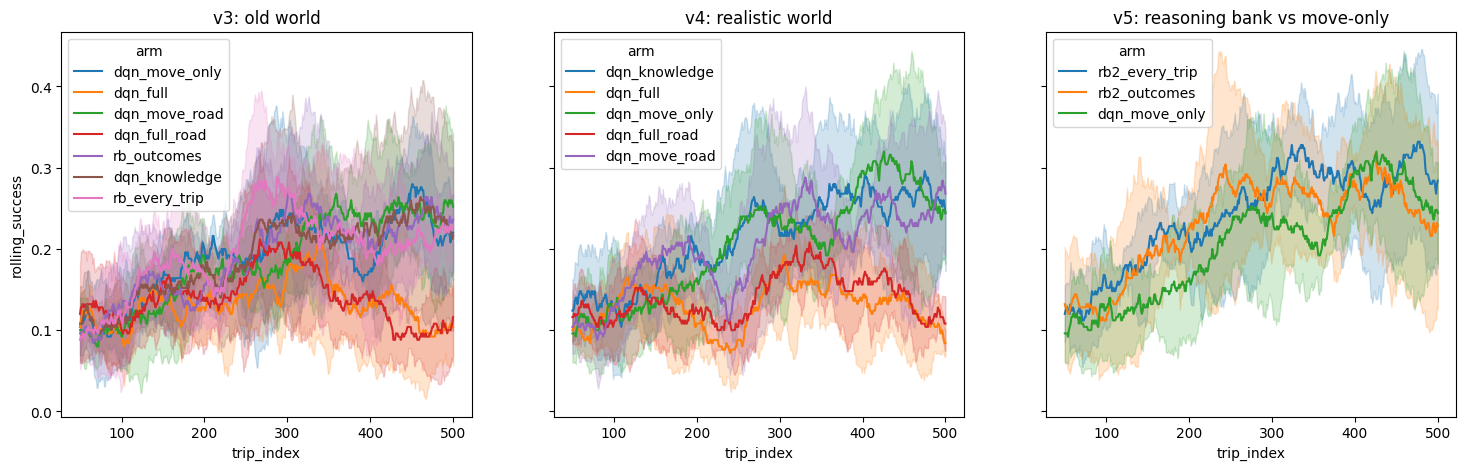

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Panel A: v3 ablation (old world), all DQN arms
v3_panel = curves[(curves['version'] == 'v3')]
# Panel B: v4 ablation (realistic world), all DQN arms
v4_panel = curves[(curves['version'] == 'v4')]
# Panel C: Q3 — v5 rb2 arms PLUS v4 dqn_move_only as the baseline (same world, same base code)
v5_panel = curves[(curves["version"] == "v5") | ((curves["version"] == "v4") & (curves["arm"] == "dqn_move_only"))]


for ax, data, title in [(axes[0], v3_panel, "v3: old world"),
                        (axes[1], v4_panel, "v4: realistic world"),
                        (axes[2], v5_panel, "v5: reasoning bank vs move-only")]:
    sns.lineplot(data=data, x="trip_index", y="rolling_success", hue="arm", errorbar="sd", ax=ax)
    ax.set_title(title)

In [ ]:
# Mean trip success scores
# Area under curve
auc = (train[train["trip_index"] <= 500]
       .groupby(["version", "arm", "seed"])["poacher_success"]
       .mean()
       .rename("auc")
       .reset_index())

auc

mean    std
version arm                         
v3      dqn_full        0.130  0.021
        dqn_full_road   0.138  0.018
        dqn_knowledge   0.186  0.051
        dqn_move_only   0.188  0.020
        dqn_move_road   0.185  0.015
        rb_every_trip   0.191  0.037
        rb_outcomes     0.186  0.027
v4      dqn_full        0.126  0.029
        dqn_full_road   0.137  0.012
        dqn_knowledge   0.210  0.025
        dqn_move_only   0.201  0.029
        dqn_move_road   0.198  0.021
v5      rb2_every_trip  0.238  0.027
        rb2_outcomes    0.226  0.052

In [34]:
# Pulling V5 RB and DQN to compare speed of learning
baseline = auc[(auc["version"] == "v4") & (auc["arm"] == "dqn_move_only")]["auc"]
rb       = auc[(auc["version"] == "v5") & (auc["arm"] == "rb2_every_trip")]["auc"]
print(baseline.round(3).tolist())
print(rb.round(3).tolist())

[0.212, 0.2, 0.242, 0.182, 0.168]
[0.274, 0.232, 0.256, 0.208, 0.222]


In [ ]:
print(f"V5DQN: mean: {baseline.mean()}, std: {baseline.std()}")
print(f"V5 RB: mean: {rb.mean()}, std: {rb.std()}")

V5DQN: mean: 0.2008, std: 0.028516661796220113
V5 RB: mean:0.2384, std: 0.0265103753274072


In [41]:
#grouping spreads might differ, given seed performance variability
from scipy import stats
stats.ttest_ind(rb, baseline, equal_var=False)

TtestResult(statistic=np.float64(2.159351021435164), pvalue=np.float64(0.06303122398967963), df=np.float64(7.957798036547223))

In [42]:
pairs = [
    ("success", runs, ("v4", "dqn_move_only"), ("v4", "wanderer")),
    ("success", runs, ("v4", "dqn_move_only"), ("v4", "shortest_path")),
    ("success", runs, ("v4", "dqn_knowledge"), ("v4", "dqn_move_only")),
    ("success", runs, ("v4", "dqn_full"),      ("v4", "dqn_move_only")),
    ("auc",     auc,  ("v5", "rb2_every_trip"), ("v4", "dqn_move_only")),
    ("success", runs, ("v5", "rb2_every_trip"), ("v4", "dqn_move_only")),
    ("caught",  runs, ("v5", "rb2_every_trip"), ("v4", "dqn_move_only")),
]

rows = []
for metric, table, a, b in pairs:
    x = table[(table["version"] == a[0]) & (table["arm"] == a[1])][metric]   # chunk 1
    y = table[(table["version"] == b[0]) & (table["arm"] == b[1])][metric]
    result = stats.ttest_ind(x, y, equal_var=False)                          # chunk 3
    rows.append({"metric": metric, "A": a[1], "B": b[1],
                 "mean_A": x.mean(), "mean_B": y.mean(), "p": result.pvalue})

pd.DataFrame(rows).round(3)

,metric,A,B,mean_A,mean_B,p
0,success,dqn_move_only,wanderer,0.303,0.070,0.000
1,success,dqn_move_only,shortest_path,0.303,0.357,0.026
2,success,dqn_knowledge,dqn_move_only,0.174,0.303,0.036
3,success,dqn_full,dqn_move_only,0.099,0.303,0.000
4,auc,rb2_every_trip,dqn_move_only,0.238,0.201,0.063
5,success,rb2_every_trip,dqn_move_only,0.260,0.303,0.280
6,caught,rb2_every_trip,dqn_move_only,0.045,0.302,0.002
